# 06 Character-level CNN, revised (Model 2b)

The CNN of `03_charcnn.ipynb` (Gregório et al., 2024, Figure 1) with four changes to its architecture. Each change fixes a weakness found in the trained Model 2 of 03 (measured on 20,000 validation domains). Everything else is the same as in 03: the data, the two setups, the loss, the training settings and the metrics, so a difference in the results comes from the architecture alone.

| Change | Model 2 (03, the paper) | Model 2b (this notebook) | Why |
|---|---|---|---|
| 1. End of the network | flatten: 93 positions x 30 filters = 2,790 numbers, one weight each | for each filter, its maximum and its mean over the real characters, plus the domain length | The paper's pools have stride 1, so the sequence keeps its 93 positions, and the dense layer has to learn each pattern again at every position. |
| 2. Width | 500, 250, 60, 60, 30, 30 filters, then a dense layer of 15 | 128 filters in every convolution, a dense layer of 128 | The end is a bottleneck: in the binary model, 6 of the 15 dense units and 11 of the 30 last filters never activate. |
| 3. Overfitting | L1 and L2 penalties only | also dropout before and after the dense layer, and batch normalization after every convolution | The validation loss is lowest at epoch 9 (binary) and 13 (family), then rises. |
| 4. Padding | read as characters, although it fills 83% of the 93 positions | ignored: kept at zero, left out of the pooling and the batch normalization, and each batch is cut to its longest domain | The output does not depend on the padding, and a domain costs about 5 times fewer multiply-adds (about 18 M instead of 99 M). |

The six convolutions keep the paper's kernel sizes (7, 6, 5, 5, 4, 3).

It is run in two setups, like Model 2: **binary** (target DGA/legitimate) and **family-first** (target `legit` or a DGA family, collapsed with P(DGA) = 1 - P(legit)). The input is the full domain name as it is, TLD included (nothing is split off), and both setups use the sample weights. Metrics are computed on the DGA/legitimate decision, on the validation set; the test set is kept for the final results.

After loading and encoding the data, the notebook follows four steps:

1. **Define a predictor**: the revised CNN, which gives each domain a probability for every class.
2. **Define a loss**: weighted cross-entropy plus L1 and L2 penalties on the weights.
3. **Optimize the loss**: Adam on mini-batches, keeping the best epoch on validation.
4. **Test the model**: metrics on the DGA/legitimate decision, compared with Model 2, and the latent spaces of both models: which DGA families each one mixes with legitimate domains or with each other, and what to do about it.

The notebook defines each step and runs it; the code it uses is in `src/models/`:

- `charcnn2.py`: the architecture of the revised CNN (`charcnn.py`: Model 2, for the comparison).
- `train.py`: the training loop (`fit`), which saves every epoch and continues an interrupted training.
- `tracking.py`: MLflow tracking of the runs, shared by every notebook.
- `plots.py`: the loss plot, redrawn after every epoch, and the latent-space plots.
- `latent.py`: the latent space of a trained CNN, and the conflicts in it.
- `metrics.py`: the metrics, shared with the baselines.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

## Settings

Training is the same as in 03, which follows the paper (Table 2): Adam, learning rate 1e-4, batch size 250, L1 1e-5 and L2 1e-4, keeping the best epoch on validation (here by macro-F1). It runs for 40 epochs instead of the paper's 20, as in 03. The new settings are the size of the revised CNN: `WIDTH` filters in every convolution, `HIDDEN` units in the dense layer, and the `DROPOUT` rate. On a CPU one epoch over the full training set still takes a long time, so use a GPU (e.g. Colab) for `SAMPLE = None`.

Each setup is saved after every epoch in its folder of `RUN_DIRS`, and tracked as one run of the MLflow experiment `MLFLOW_EXPERIMENT`: `charcnn`, the same as 03, so the two CNNs are side by side in MLflow. `PAPER_DIRS` are the folders of the trained Model 2 of 03, used for the comparison at the end.

In [2]:
SAMPLE = None   # None = full training set
EPOCHS = 40
LR = 1e-4          # Adam learning rate
BATCH_SIZE = 250
L1, L2 = 1e-5, 1e-4   # penalties on the convolution and dense weights
WIDTH = 128        # filters in every convolution
HIDDEN = 128       # units in the dense layer
DROPOUT = 0.5      # dropout rate, before and after the dense layer
SEED = 0
EVAL_SET = "val"   # "test" only for the final results
WEIGHTED = True    # use the sample weights in the loss
CHECKPOINTS = ROOT / "checkpoints"   # trained models are saved here (not committed)
RUN = 1            # run number in the folder names below; a new number starts a new run
RUN_DIRS = {"binary": CHECKPOINTS / f"checkpoints_binary_cnn2_{RUN}",
            "family": CHECKPOINTS / f"checkpoints_multifamily_cnn2_{RUN}"}
PAPER_DIRS = {"binary": CHECKPOINTS / "checkpoints_binary_cnn_1",        # Model 2 (03)
              "family": CHECKPOINTS / "checkpoints_multifamily_cnn_1"}
MLFLOW_EXPERIMENT = "charcnn"   # stored in mlruns/ (not committed); the same as 03

In [3]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from src.data.dataset import load_splits, sample_weights
from src.models import tracking
from src.models.charcnn import CharCNN     # Model 2, for the comparison
from src.models.charcnn2 import CharCNN2
from src.models.encoding import class_codes, encode
from src.models.metrics import binary_metrics, recall_per_family
from src.models.plots import plot_losses
from src.models.train import (Split, fit, load_history, p_dga, penalty, pick_device,
                              predict_proba, set_seed)

device = pick_device()
print("device:", device, torch.cuda.get_device_name() if device.type == "cuda" else "")

train_full, val, test = load_splits()
train = train_full.sample(n=SAMPLE, random_state=SEED) if SAMPLE else train_full
evaluate = test if EVAL_SET == "test" else val
y_val = (val["label"] == "dga").astype(int).to_numpy()
y_eval = (evaluate["label"] == "dga").astype(int).to_numpy()
print(f"train: {len(train):,} rows (of {len(train_full):,}), "
      f"{EVAL_SET}: {len(evaluate):,} rows")

c:\Users\User\anaconda3\envs\chimera_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda NVIDIA GeForce GTX 1650
train: 1,599,468 rows (of 1,599,468), val: 199,933 rows


## Input encoding

The full domain name, TLD included, is the input. Each character becomes its ASCII code, padded with 0 at the end to 93 characters, the longest domain in the dataset, so no domain is cut (the paper used 70, the longest in its data). Classes are numbered from the full training set, so every family has an output even if a sample misses it.

The revised CNN ignores the padding: it cuts each batch to its longest domain, so the 93 characters only set the size of the encoded arrays.

In [4]:
x_train, x_val, x_eval = (encode(part["domain"]) for part in (train, val, evaluate))
classes = {"label": sorted(train_full["label"].unique()),
           "family": sorted(train_full["family"].unique())}
print(f"input: {x_train.shape}, {len(classes['family'])} family classes")
print(train["domain"].iloc[0], "->", x_train[0][:20], "...")

input: (1599468, 93), 104 family classes
004a512fa73707a0a20da6ff6d64f1ab.co.cc -> [ 48  48  52  97  53  49  50 102  97  55  51  55  48  55  97  48  97  50
  48 100] ...


## 1. Define a predictor

The predictor is the revised CNN (`src/models/charcnn2.py`):

```text
embedding 256 -> 60, index 0 = padding (kept at zero)
conv 128 x 7, conv 128 x 6, conv 128 x 5, conv 128 x 5, conv 128 x 4, conv 128 x 3
    each followed by batch normalization (over the real characters) and a ReLU
max and mean of each filter over the real characters (2 x 128), log(length) -> 257
dropout 0.5, dense 128 + ReLU, dropout 0.5, output layer
```

Like Model 2, it maps an encoded domain to one score (logit) per class, and a softmax turns the scores into probabilities. The classes are `dga` and `legit` in the binary setup, and `legit` plus the DGA families in the family-first setup. In both, the DGA probability is P(DGA) = 1 - P(legit).

The maximum of a filter says whether its pattern (e.g. a run of hex digits, or a TLD) is anywhere in the domain, and its mean how much of the domain has it; both are the same wherever the pattern is. The length is given separately because the pooling loses it (Model 2 read it from where the padding starts).

In [5]:
SETUPS = {"binary": "label", "family": "family"}   # setup -> target column


def make_predictor(task):
    """A new, untrained revised CNN with one output per class of `task`."""
    return CharCNN2({task: len(classes[task])}, width=WIDTH, hidden=HIDDEN, dropout=DROPOUT)


def predict_p_dga(model, x, task):
    """P(DGA) = 1 - P(legit), from the softmax over the classes of `task`."""
    return p_dga(predict_proba(model, x), task, classes)


model = make_predictor("family")
print(model)
paper_size = sum(p.numel() for p in CharCNN({"family": len(classes["family"])}).parameters())
print(f"{sum(p.numel() for p in model.parameters()):,} parameters (Model 2: {paper_size:,})")

CharCNN2(
  (embedding): Embedding(256, 60, padding_idx=0)
  (convs): ModuleList(
    (0): ConvBlock(
      (conv): Conv1d(60, 128, kernel_size=(7,), stride=(1,), padding=same)
      (norm): MaskedBatchNormReLU(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ConvBlock(
      (conv): Conv1d(128, 128, kernel_size=(6,), stride=(1,), padding=same)
      (norm): MaskedBatchNormReLU(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (2-3): 2 x ConvBlock(
      (conv): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=same)
      (norm): MaskedBatchNormReLU(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (4): ConvBlock(
      (conv): Conv1d(128, 128, kernel_size=(4,), stride=(1,), padding=same)
      (norm): MaskedBatchNormReLU(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (5): ConvBlock(
      (conv): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=sam

Before training, the weights are random, so the predictor cannot yet tell DGA from legitimate. The padding does not change its output: the same domains padded to 93 characters (as everywhere in this notebook) or to 40 get exactly the same P(DGA).

In [6]:
examples = val.groupby("label").head(3)
model = make_predictor("label")
pd.DataFrame({"domain": examples["domain"].to_numpy(),
              "label": examples["label"].to_numpy(),
              "P(DGA), untrained": predict_p_dga(model, encode(examples["domain"]), "label").round(3),
              "padded to 40": predict_p_dga(model, encode(examples["domain"], max_len=40),
                                            "label").round(3)})

c:\Users\User\anaconda3\envs\chimera_gpu\Lib\site-packages\torch\nn\modules\conv.py:370: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1037.)
  return F.conv1d(


,domain,label,"P(DGA), untrained",padded to 40
0,016ff90221934b15f2b2fa291e91c212.info,dga,0.520,0.520
1,029d23144d4bd429e9639b06b7a4050d.cz.cc,dga,0.520,0.520
2,029d23144d4bd429e9639b06b7a4050d.org,dga,0.520,0.520
3,0-1.ir,legit,0.515,0.515
4,0-audiobooks.com,legit,0.518,0.518
5,000919.cn,legit,0.516,0.516


## 2. Define a loss

The loss is the same as in 03. The loss of a batch of $B$ domains is the paper's loss (Table 2) with the sample weights added:

$$L = \frac{1}{B}\sum_{i=1}^{B} w_i \,\big(-\log P(y_i \mid x_i)\big) \;+\; \lambda_1 \sum |W| \;+\; \lambda_2 \sum W^2$$

- The first term is the cross-entropy: minus the log of the probability the predictor gives to the true class $y_i$ of domain $x_i$, weighted by its sample weight $w_i$. With `WEIGHTED = False`, every $w_i$ is 1.
- The other two terms are the L1 ($\lambda_1$ = 1e-5) and L2 ($\lambda_2$ = 1e-4) penalties on the convolution and dense weights $W$ (not the embedding, the biases or the batch normalization), added as Keras does (`penalty` in `src/models/train.py`).

In [7]:
def loss_fn(model, logits, y, w, task):
    """Loss of one batch: weighted cross-entropy + L1/L2 penalty on the weights."""
    cross_entropy = F.cross_entropy(logits[task], y, reduction="none")   # -log P(y_i | x_i)
    return (cross_entropy * w).mean() + penalty(model, L1, L2)

The loss of the untrained binary predictor on the first batch of the training set:

In [8]:
xb = torch.as_tensor(x_train[:BATCH_SIZE])
yb = torch.as_tensor(class_codes(train["label"].iloc[:BATCH_SIZE], classes["label"]))
wb = torch.as_tensor(np.array(train["weight"].iloc[:BATCH_SIZE]) if WEIGHTED
                     else np.ones(BATCH_SIZE), dtype=torch.float32)
with torch.no_grad():
    loss = loss_fn(model, model(xb), yb, wb, "label")
    reg = penalty(model, L1, L2)
print(f"loss {loss:.4f} = weighted cross-entropy {loss - reg:.4f} + penalty {reg:.4f}")

loss 1.2179 = weighted cross-entropy 1.0871 + penalty 0.1308


## 3. Optimize the loss

Adam (learning rate `LR`) minimizes the loss on shuffled mini-batches of `BATCH_SIZE` domains, for `EPOCHS` epochs. After every epoch, the predictor is scored on the validation set, and the weights of the epoch with the highest macro-F1 are kept (the paper keeps the best accuracy).

Dropout and batch normalization behave differently in training and in prediction: `fit` turns dropout off and uses the batch-normalization statistics of the whole training (`model.eval()`) to score the validation set.

Two losses are recorded per epoch, both with `loss_fn`:

- $J_{train}$: the mean loss over the epoch's training batches (as Keras reports it), so it is measured while the weights are still changing, and with dropout on: it can be higher than $J_{val}$.
- $J_{val}$: the loss on the whole validation set at the end of the epoch. The validation sample weights are computed in the same way as the training ones (`sample_weights`, from the validation family sizes), so the two losses are on the same scale.

These losses are not on the same scale in the two setups: the cross-entropy of the family setup is over `legit` and every DGA family, so it also counts the DGA families taken for one another, which does not change the DGA/legitimate decision. A third number is therefore recorded per epoch, the **binary validation loss**: the weighted cross-entropy of the DGA/legitimate decision alone, with P(DGA) = 1 - P(legit) and without the penalty (`evaluate` in `src/models/train.py`). It is the loss to compare the two setups with; in the binary setup it is $J_{val}$ minus the penalty.

`optimize` puts the three pieces together: the predictor (step 1), the loss (step 2) and the Adam optimizer. The training loop that runs them is `fit` in `src/models/train.py`.

In [9]:
tracking.setup(MLFLOW_EXPERIMENT)   # the trainings below are logged to this MLflow experiment

w_train = train["weight"].to_numpy() if WEIGHTED else None
w_val = sample_weights(val) if WEIGHTED else None


def optimize(setup):
    """Train a new predictor for `setup`: Adam on loss_fn, run by fit (src/models/train.py)."""
    task = SETUPS[setup]
    set_seed(SEED)
    model = make_predictor(task)                              # step 1: the predictor
    loss = partial(loss_fn, task=task)                        # step 2: the loss
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)   # step 3: the optimizer
    history, p = fit(
        model, loss, optimizer,
        train=Split(x_train, class_codes(train[task], classes[task]), w_train),
        val=Split(x_val, class_codes(val[task], classes[task]), w_val, y_val),
        decide=task, classes=classes, folder=RUN_DIRS[setup],
        epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED, device=device,
        params={"model": "charcnn2", "setup": setup, "task": task, "sample": SAMPLE,
                "lr": LR, "l1": L1, "l2": L2, "weighted": WEIGHTED, "width": WIDTH,
                "hidden": HIDDEN, "dropout": DROPOUT})
    return model, history, p

One model per setup, each from the same seed. While a setup trains, its loss plot is redrawn after every epoch. After every epoch, `fit` saves the training in the setup's folder in `checkpoints/` (`RUN_DIRS`: `checkpoints_binary_cnn2_1` and `checkpoints_multifamily_cnn2_1` for `RUN = 1`):

- `epoch_01.pt`, `epoch_02.pt`, ...: the model weights after each epoch.
- `history.csv`: J_train, J_val, the binary validation loss and the validation metrics of every epoch so far.
- `last.pt`: everything needed to continue (weights, Adam state, shuffling state, history).
- `best.pt`: the weights of the kept epoch, written when the setup has finished.

Each setup is also an MLflow run (experiment `charcnn`, with the runs of 03, named after its folder): the settings, then J_train, J_val, the binary validation loss and the validation metrics of every epoch, and at the end the kept epoch, `history.csv`, the loss plot and the kept model. To browse the runs, run `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` from the repository root and open http://127.0.0.1:5000.

If training stops (interrupted, crash, restart), run the notebook again from the top: each setup continues from its last saved epoch, in the same MLflow run and with the same shuffling as an uninterrupted run, and a setup that has finished is only reloaded. The settings are saved with the run, and a run cannot be continued with different settings: change `RUN` to train from scratch.

--- binary (2 classes), saved in c:\Users\User\OneDrive\Documents\GitHub\dga-detection\checkpoints\checkpoints_binary_cnn2_1
40 epoch(s) already saved in checkpoints_binary_cnn2_1
--- family (104 classes), saved in c:\Users\User\OneDrive\Documents\GitHub\dga-detection\checkpoints\checkpoints_multifamily_cnn2_1


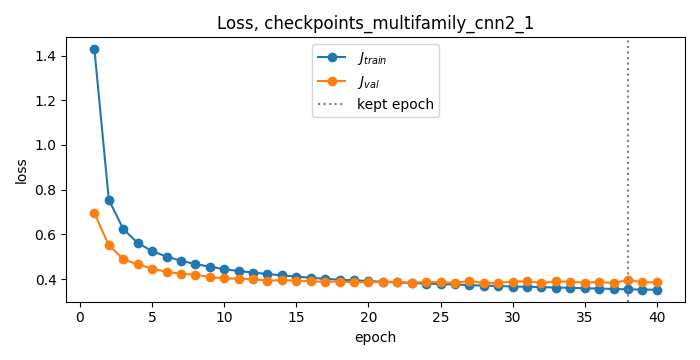

epoch  1: J_train 1.4279, J_val 0.6945 (binary 0.1163), val macro-F1 0.9621, AUC 0.9931 (191 s)
epoch  2: J_train 0.7549, J_val 0.5519 (binary 0.1008), val macro-F1 0.9678, AUC 0.9950 (192 s)
epoch  3: J_train 0.6241, J_val 0.4885 (binary 0.0898), val macro-F1 0.9699, AUC 0.9955 (190 s)
epoch  4: J_train 0.5615, J_val 0.4660 (binary 0.0894), val macro-F1 0.9707, AUC 0.9958 (191 s)
epoch  5: J_train 0.5249, J_val 0.4468 (binary 0.0823), val macro-F1 0.9729, AUC 0.9963 (192 s)
epoch  6: J_train 0.5008, J_val 0.4325 (binary 0.0797), val macro-F1 0.9753, AUC 0.9967 (191 s)
epoch  7: J_train 0.4821, J_val 0.4236 (binary 0.0793), val macro-F1 0.9737, AUC 0.9963 (191 s)
epoch  8: J_train 0.4668, J_val 0.4197 (binary 0.0792), val macro-F1 0.9745, AUC 0.9964 (191 s)
epoch  9: J_train 0.4554, J_val 0.4093 (binary 0.0757), val macro-F1 0.9755, AUC 0.9968 (190 s)
epoch 10: J_train 0.4443, J_val 0.4030 (binary 0.0756), val macro-F1 0.9750, AUC 0.9970 (190 s)
epoch 11: J_train 0.4359, J_val 0.4019 (

2026/11/18 22:15:20 WARNING mlflow.utils.requirements_utils: Found torch version (2.6.0+cu124) contains a local version label (+cu124). MLflow logged a pip requirement for this package as 'torch==2.6.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/18 22:15:30 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\User\AppData\Local\Temp\tmpjjv6062p\model\data, flavor: pytorch). Fall back to return ['torch==2.6.0', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 


kept epoch 38 (val macro-F1 0.9783)


In [10]:
models, histories, p_val = {}, {}, {}
for setup, task in SETUPS.items():
    print(f"--- {setup} ({len(classes[task])} classes), saved in {RUN_DIRS[setup]}")
    models[setup], histories[setup], p_val[setup] = optimize(setup)

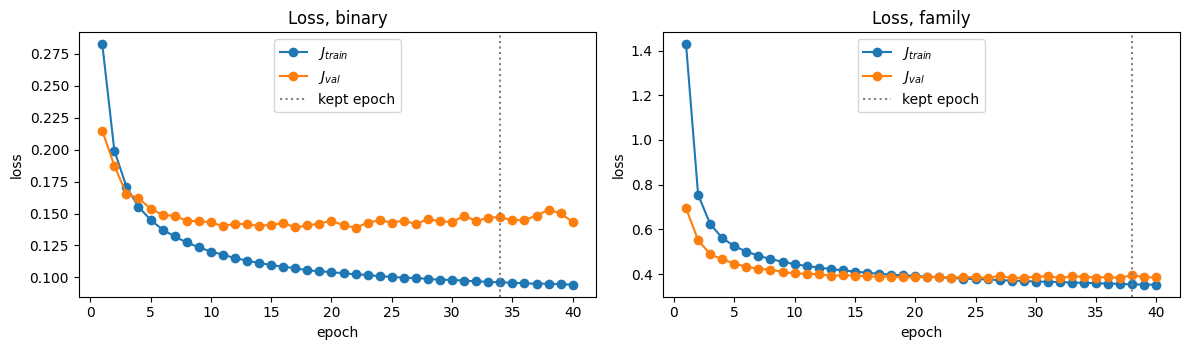

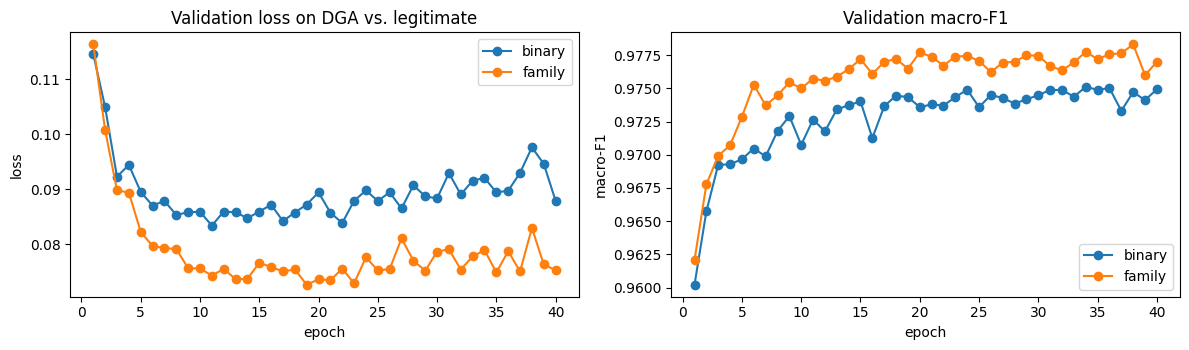

In [11]:
# The histories are read from the saved history.csv files, so this cell also plots a
# training that was interrupted (the setups and epochs saved so far).
histories = {setup: load_history(folder) for setup, folder in RUN_DIRS.items()}
histories = {setup: history for setup, history in histories.items() if history is not None}

# The loss of each setup, one panel per setup: the family loss also counts the DGA
# families taken for one another, so the two losses are not on the same scale.
fig, axes = plt.subplots(1, len(histories), figsize=(6 * len(histories), 3.6), squeeze=False)
for ax, (setup, history) in zip(axes[0], histories.items()):
    plot_losses(ax, history, f"Loss, {setup}")
fig.tight_layout()
plt.show()

# The two setups compared on the DGA/legitimate decision: the binary validation loss
# (on the same scale in both setups) and the validation macro-F1.
panels = {"val_binary_loss": ("loss", "Validation loss on DGA vs. legitimate"),
          "macro_f1": ("macro-F1", "Validation macro-F1")}
fig, axes = plt.subplots(1, len(panels), figsize=(12, 3.6))
for ax, (column, (ylabel, title)) in zip(axes, panels.items()):
    for setup, history in histories.items():
        ax.plot(history.index, history[column], marker="o", label=setup)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Test the model

Each trained predictor gives P(DGA) for every domain of the evaluation set (`EVAL_SET`: the validation set for now, the test set for the final results). A domain is called DGA when P(DGA) >= 0.5. The metrics are those of the baselines, on the DGA/legitimate decision.

In [12]:
# On the validation set, P(DGA) of the kept epoch was already computed in step 3 (same
# weights, same numbers), so the predictor only needs to run again on the test set.
p_dga_eval = {setup: p_val[setup] if EVAL_SET == "val" else predict_p_dga(models[setup], x_eval, task)
              for setup, task in SETUPS.items()}
results = {("Model 2b", setup): binary_metrics(y_eval, p) for setup, p in p_dga_eval.items()}

In [13]:
table = pd.DataFrame(results).T.round(4)
table.index.names = ["model", "setup"]
table

macro_f1  dga_precision  dga_recall  roc_auc
model    setup                                               
Model 2b binary    0.9751         0.9763      0.9739   0.9966
         family    0.9783         0.9814      0.9751   0.9974

### Recall per DGA family

Recall of each DGA family in the two setups, families ordered from largest to smallest.

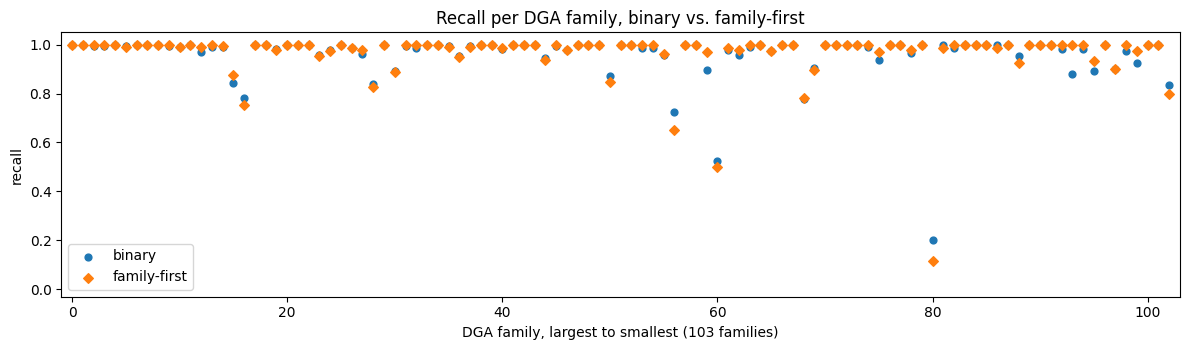

In [14]:
family_sizes = train_full.loc[train_full["label"] == "dga", "family"].value_counts()
recall = pd.DataFrame({
    setup: recall_per_family(evaluate["family"], y_eval, (p >= 0.5).astype(int))
    for setup, p in p_dga_eval.items()}).reindex(family_sizes.index)
recall.columns = ["binary", "family-first"]

fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(recall))
for setup, marker in [("binary", "o"), ("family-first", "D")]:
    ax.scatter(x, recall[setup], s=24, marker=marker, label=setup, zorder=3)
ax.set_xlim(-1, len(recall))
ax.set_ylim(-0.03, 1.05)
ax.set_xlabel(f"DGA family, largest to smallest ({len(recall)} families)")
ax.set_ylabel("recall")
ax.set_title("Recall per DGA family, binary vs. family-first")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

### Families the CNN misses most

The 10 DGA families with the lowest recall in the family-first setup.

In [15]:
recall.sort_values("family-first").head(10).round(3)

,binary,family-first
family,,
matsnu,0.200,0.118
nymaim2,0.523,0.500
gozi,0.726,0.653
qsnatch,0.781,0.754
bigviktor,0.776,0.783
lechiket,0.833,0.800
conficker,0.841,0.828
proslikefan,0.872,0.849
virut,0.845,0.877


### Comparison with Model 2 (03)

The trained Model 2 of 03 (the paper's CNN), loaded from `PAPER_DIRS` (committed in `checkpoints/`), is scored on the same evaluation set. Both models have the same data, setups, loss and training, so the differences come from the architecture.

In [16]:
paper_p = {}   # P(DGA) of Model 2 on the evaluation set, per setup
for setup, task in SETUPS.items():
    paper = CharCNN({task: len(classes[task])}).to(device)
    paper.load_state_dict(torch.load(PAPER_DIRS[setup] / "best.pt", map_location=device,
                                     weights_only=True))
    paper_p[setup] = predict_p_dga(paper, x_eval, task)

comparison = {("Model 2", setup): binary_metrics(y_eval, p) for setup, p in paper_p.items()}
comparison.update(results)
comparison = pd.DataFrame(comparison).T.round(4)
comparison.index.names = ["model", "setup"]
comparison

macro_f1  dga_precision  dga_recall  roc_auc
model    setup                                               
Model 2  binary    0.9747         0.9753      0.9739   0.9966
         family    0.9751         0.9772      0.9729   0.9966
Model 2b binary    0.9751         0.9763      0.9739   0.9966
         family    0.9783         0.9814      0.9751   0.9974

Validation curves of both models, from their saved histories: the loss on the DGA/legitimate decision and the macro-F1 per epoch (dotted: Model 2, solid: Model 2b).

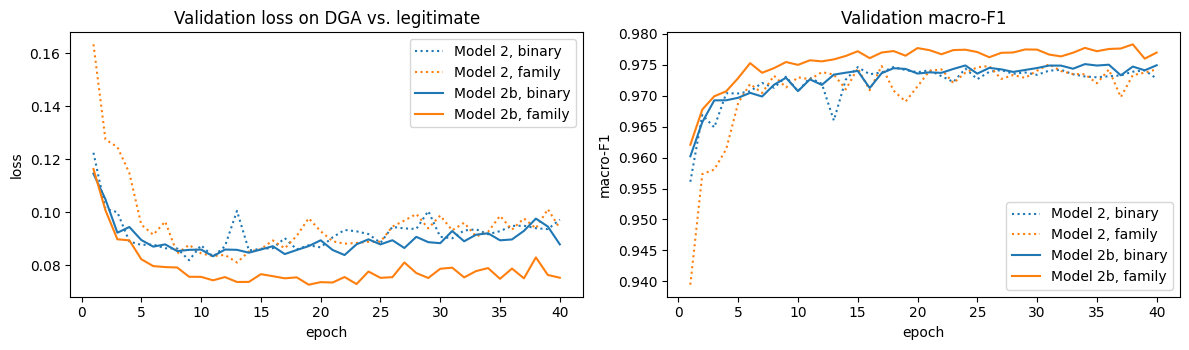

In [17]:
paper_histories = {setup: load_history(folder) for setup, folder in PAPER_DIRS.items()}
colors = {"binary": "C0", "family": "C1"}
fig, axes = plt.subplots(1, len(panels), figsize=(12, 3.6))
for ax, (column, (ylabel, title)) in zip(axes, panels.items()):
    for name, runs, style in [("Model 2", paper_histories, ":"), ("Model 2b", histories, "-")]:
        for setup, history in runs.items():
            ax.plot(history.index, history[column], linestyle=style, color=colors[setup],
                    label=f"{name}, {setup}")
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
plt.show()

Recall of the 10 DGA families that Model 2 misses most in the family-first setup, in both models.

In [18]:
paper_recall = pd.DataFrame({
    setup: recall_per_family(evaluate["family"], y_eval, (p >= 0.5).astype(int))
    for setup, p in paper_p.items()}).reindex(family_sizes.index)
paper_recall.columns = ["binary", "family-first"]
both = pd.concat({"Model 2": paper_recall, "Model 2b": recall}, axis=1)
both.loc[paper_recall.sort_values("family-first").head(10).index].round(3)

Model 2              Model 2b             
             binary family-first   binary family-first
family                                                
matsnu        0.212        0.118    0.200        0.118
nymaim2       0.559        0.539    0.523        0.500
gozi          0.751        0.754    0.726        0.653
bigviktor     0.770        0.764    0.776        0.783
virut         0.821        0.798    0.845        0.877
conficker     0.854        0.815    0.841        0.828
qsnatch       0.810        0.832    0.781        0.754
proslikefan   0.877        0.844    0.872        0.849
oderoor       0.857        0.864    0.905        0.898
nymaim        0.897        0.873    0.893        0.887

### Latent space: Model 2 vs Model 2b

The latent space of a CNN is the vector its output layer reads: the output of its dense layer, 15 numbers per domain in Model 2 and 128 in Model 2b (`src/models/latent.py`). The output layer is linear, so a domain whose latent vector sits among those of another class gets about the same prediction as them: the model cannot tell them apart. Comparing the two latent spaces shows which architecture separates DGA from legitimate domains, and the DGA families from each other, and where each one fails.

Every model sees the same validation domains: up to 100 per DGA family (so every family is seen, even the smallest) and as many legitimate domains. What a domain is mixed with is measured by its 15 nearest neighbours in the full latent space:

- **DGA vs legitimate**: the share of neighbours with the same label. A DGA domain whose neighbours are mostly legitimate is likely missed; a legitimate domain whose neighbours are mostly DGA is likely a false alarm.
- **DGA families**: the share of a DGA domain's neighbours that are of its own family, averaged per family. Only the family-first models were trained to tell the families apart, so this view is shown for the family setup only.

For each setup with both models trained (about 1 minute per model, for the 2-D maps):

1. **The maps** (t-SNE pictures of the latent space): gray = legitimate, aqua = DGA, ink = a domain in conflict; fewer ink points = better separated. The worst families (or pairs of families) are named where they sit. A map keeps who is next to whom but not the distances: it shows *where* the conflicts are, the percentages are the evidence.
2. **The rankings**: the DGA families most mixed with legitimate domains, and the pairs of DGA families most mixed with each other, one marker per model (orange: Model 2, blue: Model 2b). Lower is better; the gap between the two markers is the difference between the architectures for that family.
3. **The verdict**: the scores of both models, and the better one.
4. **What to do**: one row per conflict found in the model that separates DGA from legitimate best, with examples of the domains involved and the action to take.

In [19]:
from IPython.display import display

from src.models import latent
from src.models.plots import plot_conflicts, plot_latent

ARCHITECTURES = {   # name -> (a new model for a task, its checkpoint folders)
    "Model 2": (lambda task: CharCNN({task: len(classes[task])}), PAPER_DIRS),
    "Model 2b": (make_predictor, RUN_DIRS)}
sample = latent.sample_domains(evaluate, per_family=100, seed=SEED)   # the same for every model
x_sample = encode(sample["domain"])

spaces = {}   # setup -> {model name: its latent space}
for setup, task in SETUPS.items():
    missing = [f"{name} ({dirs[setup].name})" for name, (_, dirs) in ARCHITECTURES.items()
               if not (dirs[setup] / "best.pt").exists()]
    if missing:
        print(f"{setup}: skipped, not trained yet: {', '.join(missing)}")
        continue
    spaces[setup] = {}
    for name, (make, dirs) in ARCHITECTURES.items():
        model = make(task).to(device)
        model.load_state_dict(torch.load(dirs[setup] / "best.pt", map_location=device,
                                         weights_only=True))
        spaces[setup][name] = latent.LatentSpace(latent.embed(model, x_sample), sample, seed=SEED)
print(f"{len(sample):,} domains ({sample['family'].nunique() - 1} DGA families); "
      f"latent spaces of the {' and '.join(spaces) or 'no'} setup(s)")

18,506 domains (103 DGA families); latent spaces of the binary and family setup(s)


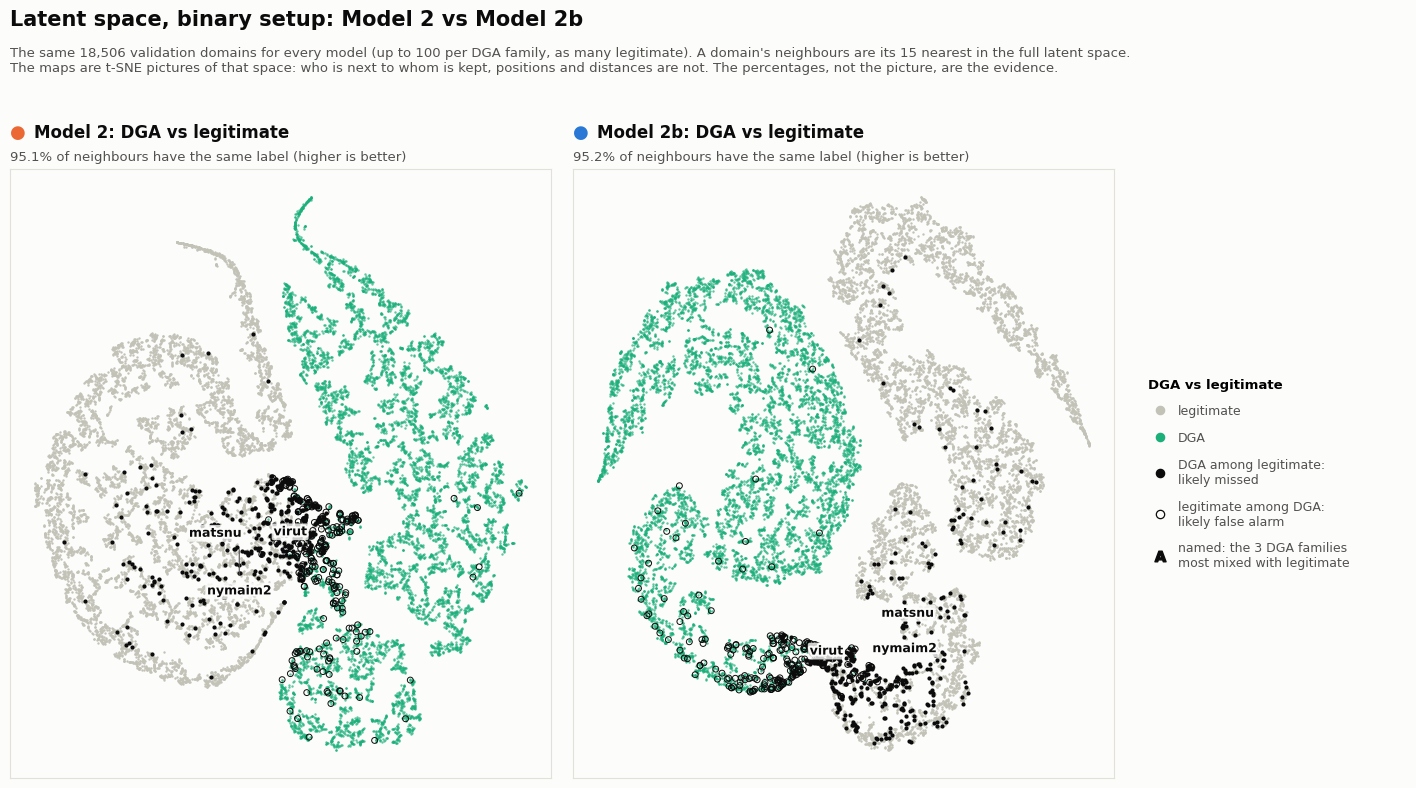

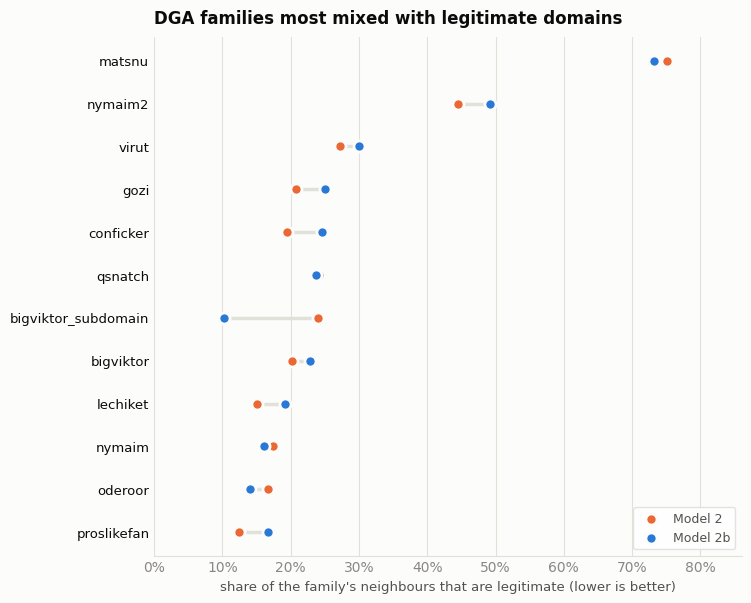

,DGA vs legitimate: neighbours with the same label
Model 2,95.1%
Model 2b,95.2%
better,Model 2b


What to do (binary setup), from the latent space of Model 2b, the better on DGA vs legitimate:


conflict,who,how much,examples,what to do
DGA family among legitimate domains,matsnu,73% of its neighbours are legitimate (Model 2: 75%),"gardenlawnplenty.com, blogcableboundary.com, devillunchheat.com","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,nymaim2,49% of its neighbours are legitimate (Model 2: 44%),"transparencyprojector.com, summary-preview.com, sagem-directory.org","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,virut,30% of its neighbours are legitimate (Model 2: 27%),"dotocu.com, nnmchm.com, iggsdb.com","Its names are short (median 6 characters), as short as many legitimate names: too few characters to tell them apart. A character model alone will keep missing some: add features beyond the name (e.g. DNS behaviour), or accept the lower recall."
DGA family among legitimate domains,gozi,25% of its neighbours are legitimate (Model 2: 21%),"installationunl.com, sourcecoreinstated.com, thethetbinstrum.com","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,conficker,25% of its neighbours are legitimate (Model 2: 19%),"fppsarih.org, eashd.org, mmchub.com","Its names are short (median 8 characters), as short as many legitimate names: too few characters to tell them apart. A character model alone will keep missing some: add features beyond the name (e.g. DNS behaviour), or accept the lower recall."
legitimate domains among DGA domains,2.5% of legitimate domains,"most of their neighbours are DGA, mostly virut, conficker, gozi","cogdzie.info, disfrutaelfujitsu.com, bkaklbu.com","Likely false alarms: legitimate names that look generated. Check them against an allow-list of known domains, or look at the precision/recall trade-off of the 0.5 threshold."


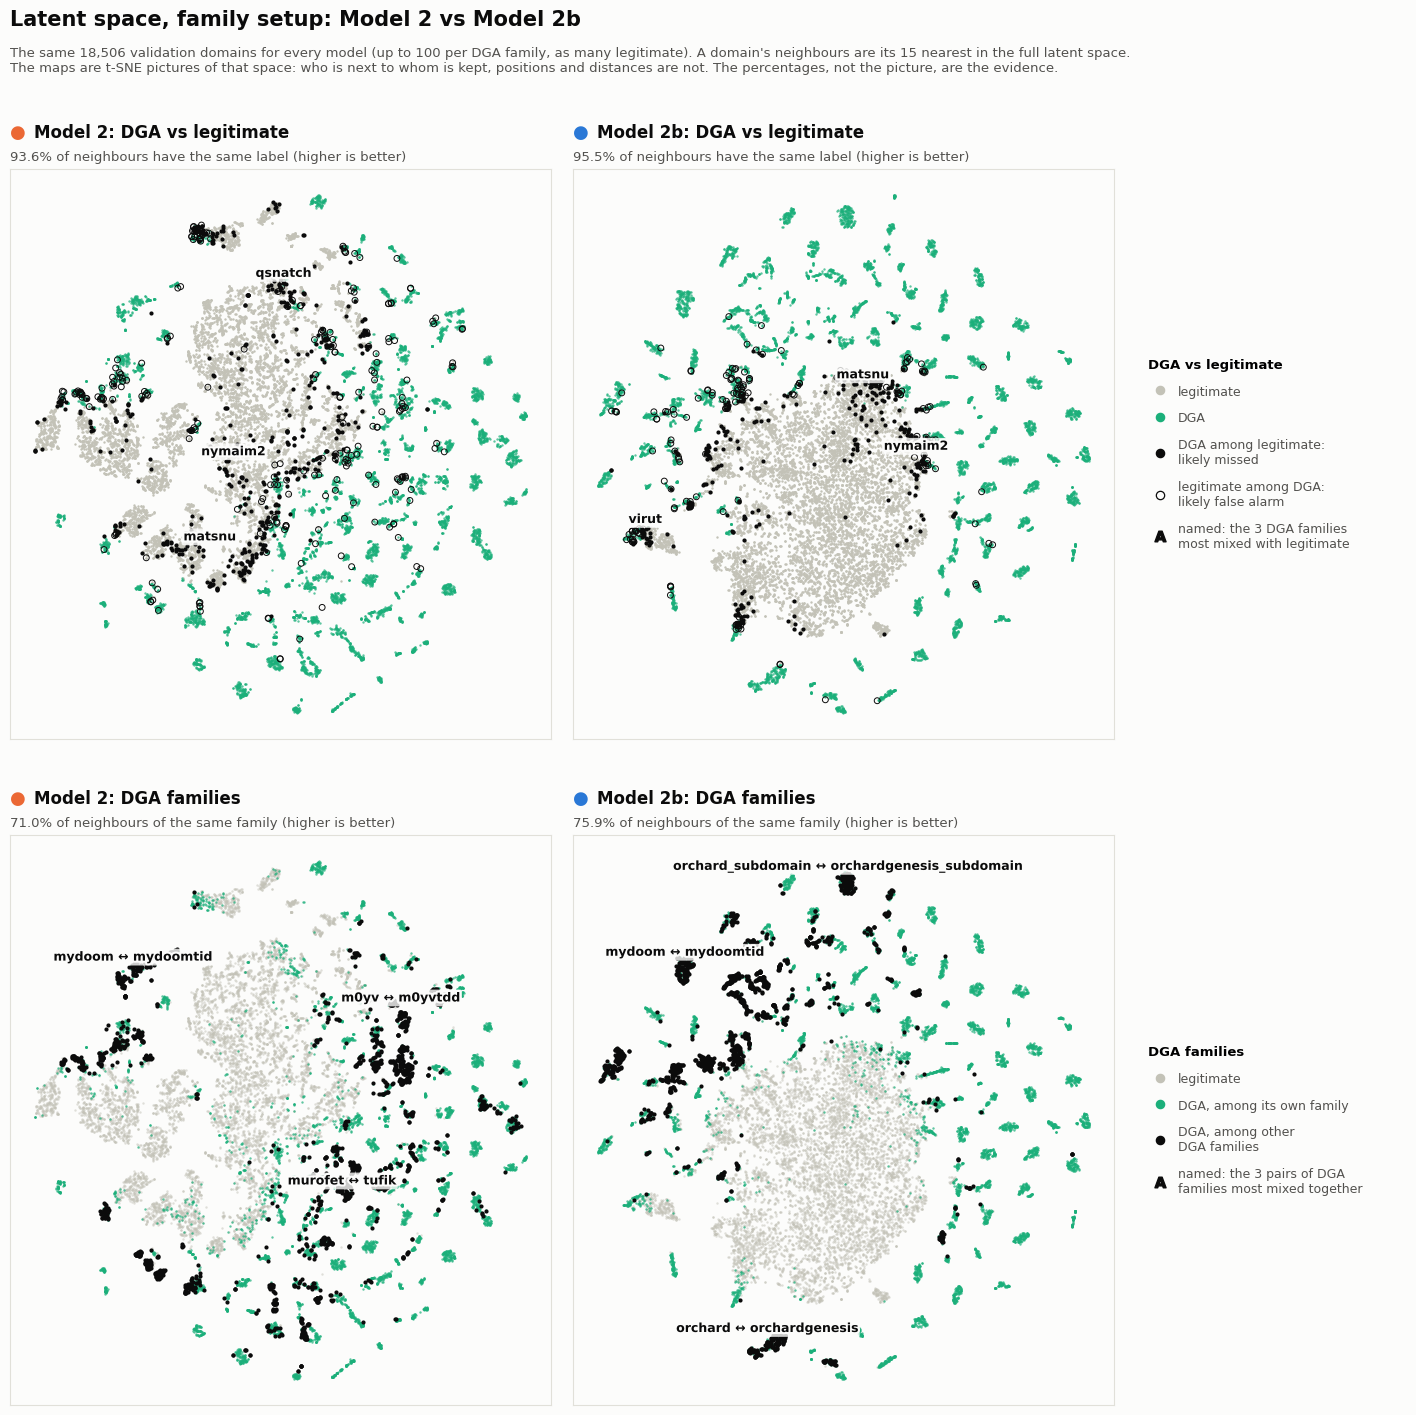

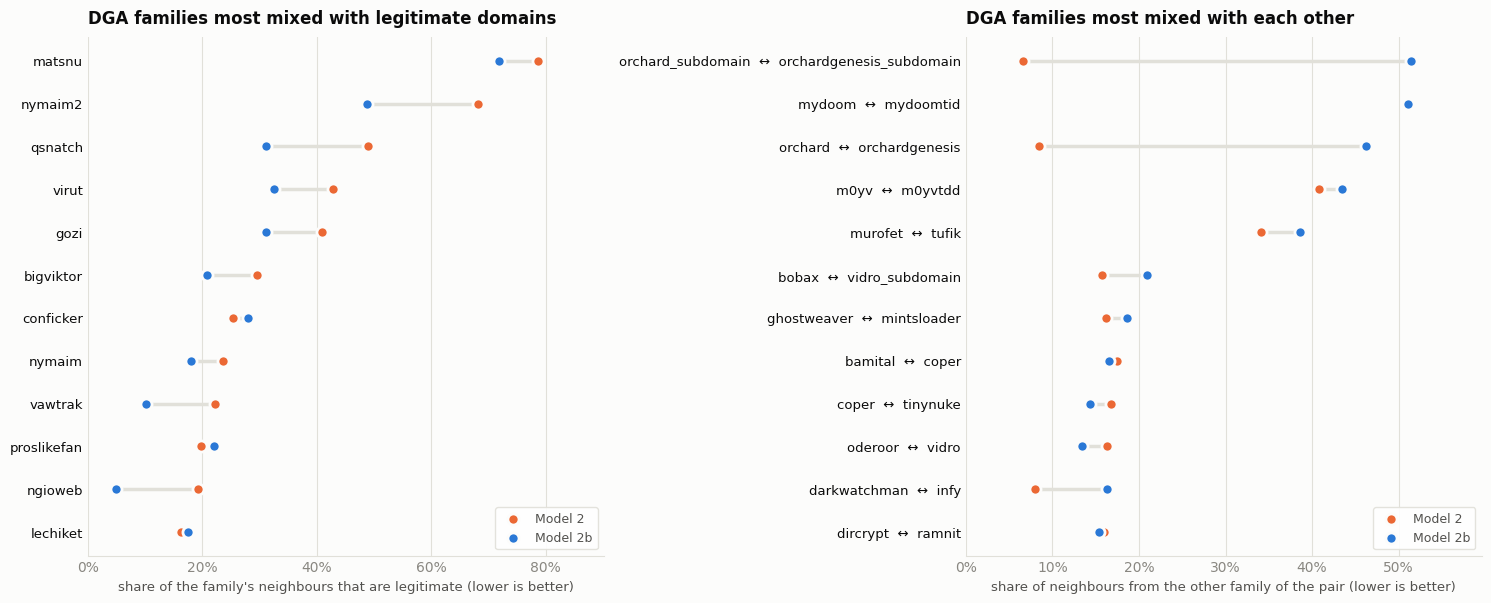

,DGA vs legitimate: neighbours with the same label,DGA families: neighbours of the same family
Model 2,93.6%,71.0%
Model 2b,95.5%,75.9%
better,Model 2b,Model 2b


What to do (family setup), from the latent space of Model 2b, the better on DGA vs legitimate:


conflict,who,how much,examples,what to do
DGA family among legitimate domains,matsnu,72% of its neighbours are legitimate (Model 2: 79%),"censuslouisville.com, readingbebars.com, powermusicians.com","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,nymaim2,49% of its neighbours are legitimate (Model 2: 68%),"realityodds.me, rebeldecline.nu, solvinginsects.com","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,virut,33% of its neighbours are legitimate (Model 2: 43%),"dotocu.com, nnmchm.com, beurfa.com","Its names are short (median 6 characters), as short as many legitimate names: too few characters to tell them apart. A character model alone will keep missing some: add features beyond the name (e.g. DNS behaviour), or accept the lower recall."
DGA family among legitimate domains,gozi,31% of its neighbours are legitimate (Model 2: 41%),"asslconditions.com, exacomparisons.com, exercisepowerand.biz","Its names are made of real words, as legitimate names are: the characters cannot tell them apart. Add word-level features (dictionary words, word n-grams) or more of its examples; expect low recall for it until then."
DGA family among legitimate domains,qsnatch,31% of its neighbours are legitimate (Model 2: 49%),"2sfes.net, iet.com.br, 6fxs.co","Its names are short (median 4 characters), as short as many legitimate names: too few characters to tell them apart. A character model alone will keep missing some: add features beyond the name (e.g. DNS behaviour), or accept the lower recall."
legitimate domains among DGA domains,2.0% of legitimate domains,"most of their neighbours are DGA, mostly virut, matsnu, qsnatch","cogdzie.info, hilti.biz, iifpiposof.net","Likely false alarms: legitimate names that look generated. Check them against an allow-list of known domains, or look at the precision/recall trade-off of the 0.5 threshold."
two DGA families mixed together,orchard_subdomain ↔ orchardgenesis_subdomain,51% of their neighbours are of the other family,0756293c.duckdns.org | 42ee3e79.duckdns.org,"Both are DGA, so DGA vs legitimate is not affected. For family attribution: merge the two classes, or check whether they are the same generator under two names."
two DGA families mixed together,mydoom ↔ mydoomtid,51% of their neighbours are of the other family,srpanqprns.biz | rmneqshhrs.org,"Both are DGA, so DGA vs legitimate is not affected. For family attribution: merge the two classes, or check whether they are the same generator under two names."
two DGA families mixed together,orchard ↔ orchardgenesis,46% of their neighbours are of the other family,378c2a99.com | afd6616f.net,"Both are DGA, so DGA vs legitimate is not affected. For family attribution: merge the two classes, or check whether they are the same generator under two names."
two DGA families mixed together,m0yv ↔ m0yvtdd,43% of their neighbours are of the other family,aimoqa.biz | wmkkauioy.biz,"Both are DGA, so DGA vs legitimate is not affected. For family attribution: merge the two classes, or check whether they are the same generator under two names."


In [20]:
for setup, models_ in spaces.items():
    families = setup == "family"   # the family view only where the models learned the families
    plot_latent(models_, f"Latent space, {setup} setup: Model 2 vs Model 2b", families=families)
    plt.show()
    plot_conflicts(models_, families=families)
    plt.show()
    display(latent.verdict(models_, families=families))
    name, todo = latent.actions(models_, families=families)
    print(f"What to do ({setup} setup), from the latent space of {name}, "
          f"the better on DGA vs legitimate:")
    display(todo.style.hide(axis="index")
            .set_properties(**{"text-align": "left", "vertical-align": "top"}))